In [21]:
# 0. CHUẨN BỊ: tạo thư mục bài tập và kiểm tra CSV
from pathlib import Path
import numpy as np
import pandas as pd

Path("baitap05").mkdir(parents=True, exist_ok=True)
DU_LIEU_MINH_HOA = False
# Lưu dấu vân tay để lần chạy sau vẫn nhận biết tệp minh họa đã sinh.
import hashlib
import json
tep_dau_demo = Path("baitap05/.csv_minh_hoa_hash.json")
dau_demo = json.loads(tep_dau_demo.read_text(encoding="utf-8")) if tep_dau_demo.exists() else {}
tep_vua_tao = []

if not Path("khach_vay.csv").exists():
    DU_LIEU_MINH_HOA = True
    # Chỉ dùng khi thiếu dữ liệu gốc; bảng mẫu 600 khách để kiểm tra mã.
    rng = np.random.default_rng(7)
    thu_nhap_mau = np.round(rng.uniform(5, 30, 600), 1)
    thu_nhap_mau[:8] = [15.0, 15.1] * 4
    ty_le_no_mau = np.round(rng.uniform(0.1, 1.3, 600), 2)
    viec_lam_mau = rng.integers(0, 2, 600)
    phu_thuoc_mau = rng.integers(0, 5, 600)
    logit = ((thu_nhap_mau > 15.05) * 3 - 1.5
             - 2.4 * (ty_le_no_mau > 0.65) + 1.1 * viec_lam_mau
             + 0.3 * (ty_le_no_mau < 0.35) - 0.12 * phu_thuoc_mau + 0.6)
    xac_suat = 1 / (1 + np.exp(-logit))
    nhan_mau = (np.random.default_rng(107).random(600) < xac_suat).astype(int)
    pd.DataFrame({
        "thu_nhap": thu_nhap_mau,
        "ty_le_no": ty_le_no_mau,
        "co_viec_on_dinh": viec_lam_mau,
        "so_nguoi_phu_thuoc": phu_thuoc_mau,
        "tra_dung_han": nhan_mau,
    }).to_csv("khach_vay.csv", index=False)
    tep_vua_tao.append("khach_vay.csv")
    print("CHÚ Ý: khach_vay.csv đang dùng DỮ LIỆU MINH HỌA, không phải file gốc.")
else:
    print("Đã tìm thấy khach_vay.csv.")

if not Path("gia_nha.csv").exists():
    DU_LIEU_MINH_HOA = True
    # Chỉ dùng khi thiếu dữ liệu gốc; diện tích nằm trong khoảng ~45–120 m2.
    rng_nha = np.random.default_rng(42)
    dien_tich_mau = np.round(rng_nha.uniform(45, 120, 140), 1)
    gia_mau = 0.078 * dien_tich_mau + 0.35 + rng_nha.normal(0, 0.28, 140)
    pd.DataFrame({"dien_tich": dien_tich_mau,
                  "gia": np.round(gia_mau, 2)}).to_csv("gia_nha.csv", index=False)
    tep_vua_tao.append("gia_nha.csv")
    print("CHÚ Ý: gia_nha.csv đang dùng DỮ LIỆU MINH HỌA, không phải file gốc.")
else:
    print("Đã tìm thấy gia_nha.csv.")

# Nếu CSV đã có từ lần chạy trước, xác thực xem nó vẫn là dữ liệu minh họa.
for ten_csv in ["khach_vay.csv", "gia_nha.csv"]:
    hash_hien_tai = hashlib.sha256(Path(ten_csv).read_bytes()).hexdigest()
    if ten_csv in tep_vua_tao:
        dau_demo[ten_csv] = hash_hien_tai
    elif dau_demo.get(ten_csv) == hash_hien_tai:
        DU_LIEU_MINH_HOA = True
        print(f"CHÚ Ý: {ten_csv} vẫn là file DỮ LIỆU MINH HỌA của lần chạy trước.")
    else:
        dau_demo.pop(ten_csv, None)  # CSV được thay bằng dữ liệu khác.
if dau_demo:
    tep_dau_demo.write_text(json.dumps(dau_demo, indent=2), encoding="utf-8")
elif tep_dau_demo.exists():
    tep_dau_demo.unlink()

print("Thư mục chứa ảnh:", Path("baitap05").resolve())
if DU_LIEU_MINH_HOA:
    print("THAY các file CSV minh họa bằng file CSV chính thức rồi Run All để có kết quả nộp.")

Đã tìm thấy khach_vay.csv.
Đã tìm thấy gia_nha.csv.
Thư mục chứa ảnh: /content/baitap05


In [22]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

# Mười khách vay để tính tay, giống hệt bảng trên slide
nho = pd.DataFrame({
    "thu_nhap": [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han": [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y = nho["tra_dung_han"].to_numpy()


def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)


g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}")
print()

# Thử mọi ngưỡng nằm giữa hai mức thu nhập liền nhau
thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print(" nguong Gini sau chia Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f" {nguong:6.1f} {g:13.4f} {g_goc - g:9.4f}")
print()

# Câu hỏi thứ hai: có việc làm ổn định không
viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f" Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}")
print()

# Để scikit-learn tự chọn câu hỏi đầu tiên rồi so với bảng ở trên
cot = ["thu_nhap", "co_viec_on_dinh"]
cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nho[cot], y)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))

Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
 nguong Gini sau chia Gini giam
    7.0        0.4000    0.0800
    8.5        0.4750    0.0050
   10.0        0.4190    0.0610
   12.0        0.3167    0.1633
   14.0        0.4000    0.0800
   16.5        0.4500    0.0300
   19.0        0.3429    0.1371
   22.5        0.4000    0.0800
   27.5        0.4444    0.0356

Cau hoi 'co viec on dinh ?'
 Gini sau chia 0.4190, Gini giam 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



In [23]:
"""Bước 2: học một cây nhỏ năm lá trên dữ liệu khách vay rồi đọc nó."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

df = pd.read_csv("khach_vay.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))
print()

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Giới hạn cây chỉ được có 5 lá để còn đọc được bằng mắt
cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay.fit(X_tr, y_tr)

print(f"Do sau {cay.get_depth()}, so la {cay.get_n_leaves()}")
print(export_text(cay, feature_names=list(X.columns),
                  show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay.predict(X_tr))
a_kt = accuracy_score(y_te, cay.predict(X_te))
print(f"Accuracy tap hoc : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}")
print()

# Hai khách mới, đi theo cây để biết mỗi người rơi vào lá nào
moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})
du_doan = cay.predict(moi)
xac_suat = cay.predict_proba(moi)[:, 1]
for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accu

In [24]:
# -*- coding: utf-8 -*-
"""Bước 3: để cây mọc tự do, rồi chọn độ sâu bằng kiểm định chéo."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Không đặt giới hạn nào, cây chia tới khi mọi lá đều thuần
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f" do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f" tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}")
print()

# Chọn độ sâu chỉ dựa trên tập học
print("Do sau tap hoc kiem dinh cheo")
diem = {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f" {d:2d} {hoc:.4f} {diem[d]:.4f}")
d_tot = max(diem, key=diem.get)
print()

# Chọn xong mới mở tập kiểm tra, và chỉ mở một lần
tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0)
tot.fit(X_tr, y_tr)
print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Cay moc tu do
 do sau 13, so la 92
 tap hoc 1.0000, tap kiem tra 0.7667

Do sau tap hoc kiem dinh cheo
  1 0.7467 0.7244
  2 0.7711 0.7378
  3 0.8000 0.7511
  4 0.8644 0.8089
  5 0.8978 0.8333
  6 0.9133 0.8156
  7 0.9400 0.8067
  8 0.9600 0.7733
  9 0.9800 0.7800
 10 0.9911 0.7822
 11 0.9933 0.7756
 12 0.9978 0.7778
 13 1.0000 0.7733
 14 1.0000 0.7733
 15 1.0000 0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


In [25]:
# -*- coding: utf-8 -*-
"""Bước 4: kiểm chứng cây không cần chuẩn hoá dữ liệu."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)


# Cây 1: dữ liệu gốc
goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

# Cây 2: dữ liệu đã chuẩn hoá, trung bình tính trên riêng tập học
sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

# Cây 3: đổi thu nhập từ triệu đồng sang nghìn đồng
X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

print("Accuracy tren tap kiem tra")
print(f" du lieu goc : {accuracy_score(y_te, du_goc):.4f}")
print(f" da chuan hoa : {accuracy_score(y_te, du_chuan):.4f}")
print(f" thu nhap nghin dong: {accuracy_score(y_te, du_nghin):.4f}")
print()
print("So khach bi doan khac cay goc")
print(f" da chuan hoa : {(du_chuan != du_goc).sum()}")
print(f" thu nhap nghin dong: {(du_nghin != du_goc).sum()}")
print()
print("Nguong cua cau hoi goc")
print(f" du lieu goc : {goc.tree_.threshold[0]:.2f}")
print(f" thu nhap nghin dong: {nghin.tree_.threshold[0]:.2f}")

Accuracy tren tap kiem tra
 du lieu goc : 0.8533
 da chuan hoa : 0.8533
 thu nhap nghin dong: 0.8533

So khach bi doan khac cay goc
 da chuan hoa : 0
 thu nhap nghin dong: 0

Nguong cua cau hoi goc
 du lieu goc : 15.05
 thu nhap nghin dong: 15050.00


In [26]:
# -*- coding: utf-8 ---
"""Bước 5: trồng rừng ngẫu nhiên và so với một cây."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Bốc mẫu có hoàn lại: rút 450 lần từ 450 khách
rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})")
print()

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rng_fit = rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f" tap hoc : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f" tap kiem tra : {accuracy_score(y_te, rung.predict(X_te)):.4f}")
print()

print("So cay accuracy tap kiem tra")
for m in [1, 10, 50, 200, 400]:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    print(f" {m:4d} {accuracy_score(y_te, r.predict(X_te)):.4f}")
print()

# Bảng tổng kết ba mô hình trên cùng tập kiểm tra
ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}
print("Mo hinh tap hoc tap kiem tra")
for ten, mh in ba_mo_hinh.items():
    mh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mh.predict(X_tr))
    b = accuracy_score(y_te, mh.predict(X_te))
    print(f" {ten:14s} {a:.4f} {b:.4f}")

Boc 450 lan, co 286 khach khac nhau (64%)

Rung 200 cay
 tap hoc : 1.0000
 tap kiem tra : 0.9000

So cay accuracy tap kiem tra
    1 0.7933
   10 0.8467
   50 0.8733
  200 0.9000
  400 0.9000

Mo hinh tap hoc tap kiem tra
 Cay moc tu do  1.0000 0.7667
 Cay sau 5      0.8978 0.8533
 Rung 200 cay   1.0000 0.9000


In [27]:
# -*- coding: utf-8 -*-
"""Bước 6: đọc độ quan trọng của đặc trưng, và thấy giới hạn của nó."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
qt = pd.Series(rung.feature_importances_, index=X.columns)
print("Do quan trong, bon cot that")
print(qt.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(qt.sum(), 3))
print()

# Thêm một cột toàn số ngẫu nhiên, chẳng liên quan gì tới việc trả nợ
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)
qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong, them mot cot ngau nhien")
print(qt_nn.sort_values(ascending=False).round(3).to_string())

Do quan trong, bon cot that
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0

Do quan trong, them mot cot ngau nhien
thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076


In [28]:
# -*- coding: utf-8 -*-
"""Bước 7: cây quyết định cho bài toán hồi quy, trên dữ liệu giá nhà."""

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print(f"Cay hoi quy sau 3 co {cay.get_n_leaves()} la")
print(export_text(cay, feature_names=["dien_tich"], decimals=1))

print("MAE tren tap kiem tra (ty dong)")
mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f" Cay sau 3 : {mae_cay:.4f}")
print(f" Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print(" dien tich cay duong thang")
for dt, a, b in zip(can_moi["dien_tich"], cay.predict(can_moi), duong.predict(can_moi)):
    print(f" {dt:6.0f} m2 {a:6.2f} {b:6.2f}")

Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE tren tap kiem tra (ty dong)
 Cay sau 3 : 0.5039
 Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
 dien tich cay duong thang
     60 m2   4.92   5.12
    100 m2   8.32   8.24
    150 m2   9.40  12.13
    250 m2   9.40  19.91


In [29]:
# Dữ liệu dùng chung cho bài tập 1–5: không lấy thông tin từ tập kiểm tra khi chọn tham số
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

bang_khach = pd.read_csv("khach_vay.csv")
X_khach = bang_khach.drop(columns="tra_dung_han")
y_khach = bang_khach["tra_dung_han"]
X_hoc, X_kiem_tra, y_hoc, y_kiem_tra = train_test_split(
    X_khach, y_khach, test_size=0.25, random_state=17, stratify=y_khach
)
print(f"Tập học: {len(X_hoc)} khách | Tập kiểm tra: {len(X_kiem_tra)} khách")
if DU_LIEU_MINH_HOA:
    print("[KẾT QUẢ MINH HỌA – kiểm chứng lại với CSV gốc]")

Tập học: 450 khách | Tập kiểm tra: 150 khách


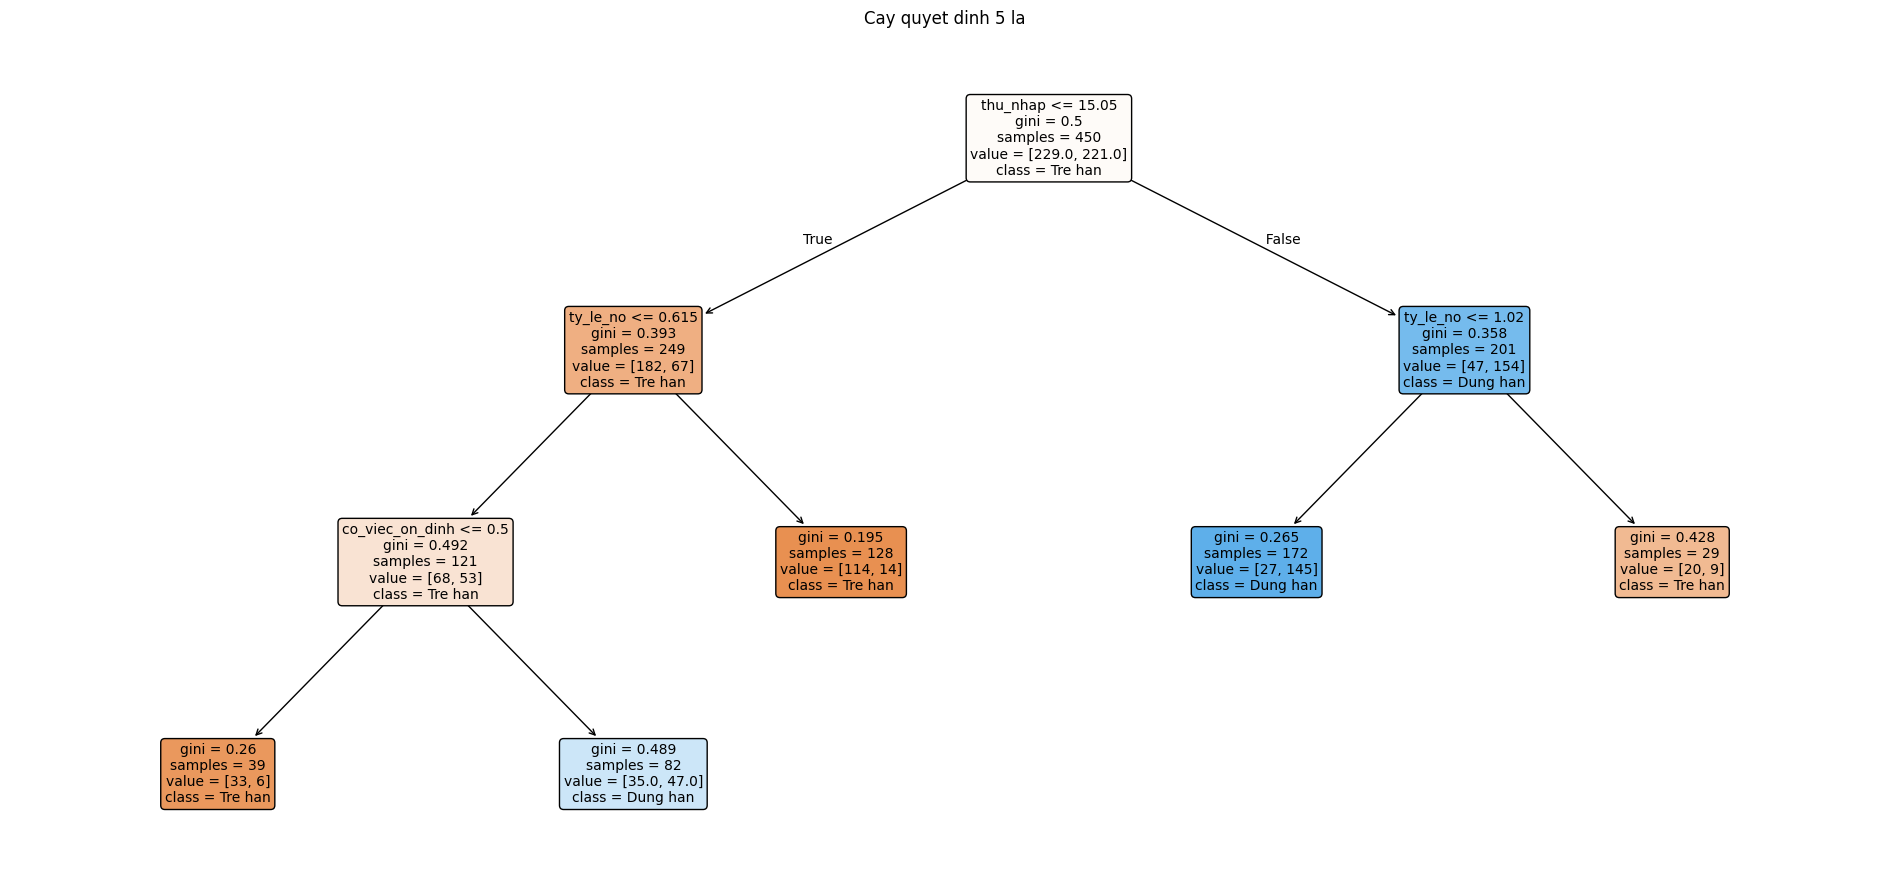

Đã lưu: baitap05/cay_nam_la.png
Số lá: 5


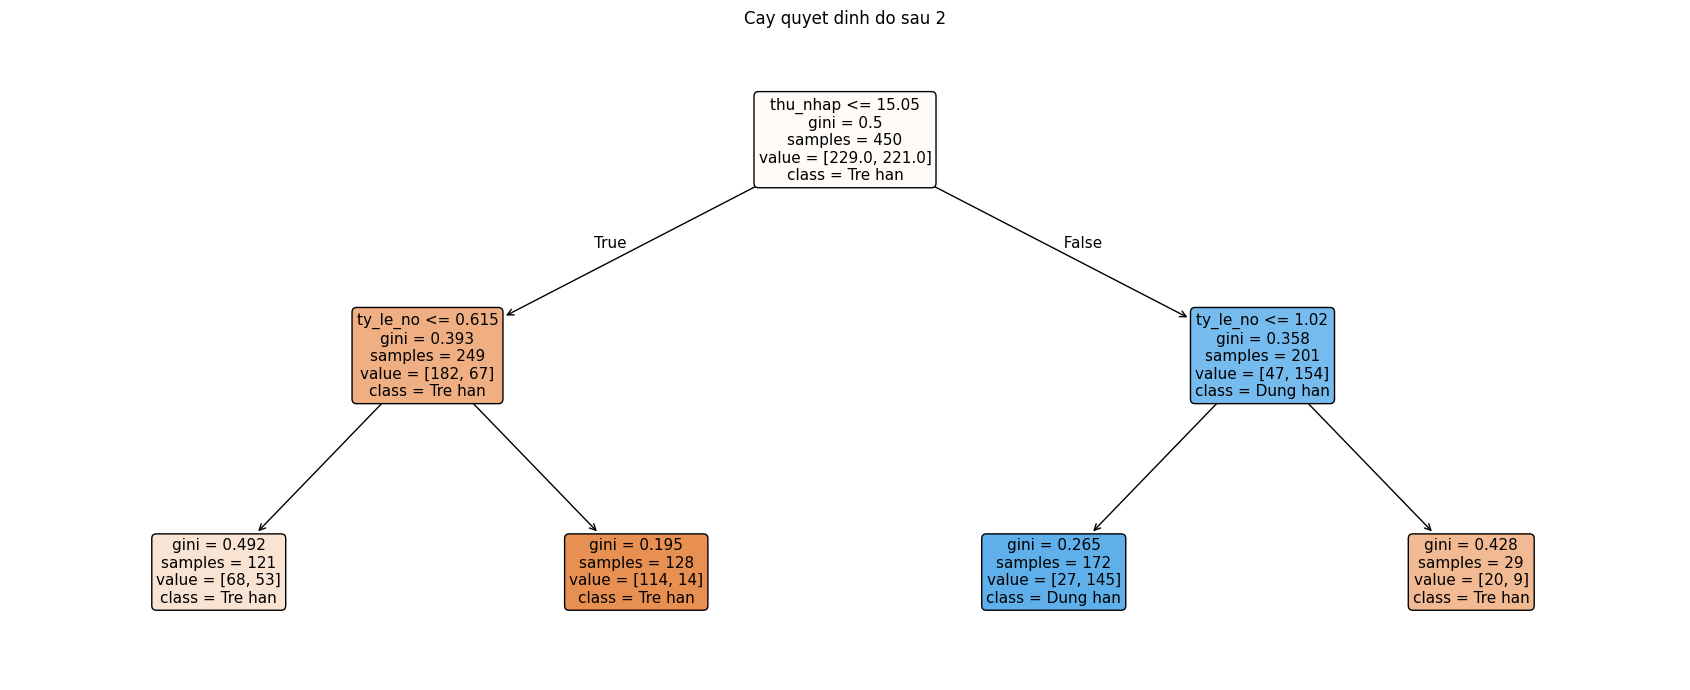

Đã lưu: baitap05/cay_sau_2.png
Hai lá bên trái: Tre han và Tre han
NHẬN XÉT: CÓ, hai lá dự đoán cùng một lớp.
Cây vẫn chia vì tỷ lệ hai lớp ở 2 nhánh khác nhau, làm giảm Gini có trọng số; không nhất thiết phải đổi nhãn dự đoán mới được chia.


In [30]:
# BÀI 1
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Vẽ lại cây có tối đa 5 lá, giống phần thực hành gốc.
cay_nam_la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay_nam_la.fit(X_hoc, y_hoc)
plt.figure(figsize=(19, 9))
plot_tree(cay_nam_la, feature_names=list(X_hoc.columns),
          class_names=["Tre han", "Dung han"], filled=True,
          rounded=True, fontsize=10)
plt.title("Cay quyet dinh 5 la")
plt.tight_layout()
plt.savefig("baitap05/cay_nam_la.png", dpi=160, bbox_inches="tight")
plt.show()
print("Đã lưu: baitap05/cay_nam_la.png")
print("Số lá:", cay_nam_la.get_n_leaves())

# 2. Vẽ cây sâu tối đa 2.
cay_sau_hai = DecisionTreeClassifier(max_depth=2, random_state=0)
cay_sau_hai.fit(X_hoc, y_hoc)
plt.figure(figsize=(17, 7))
plot_tree(cay_sau_hai, feature_names=list(X_hoc.columns),
          class_names=["Tre han", "Dung han"], filled=True,
          rounded=True, fontsize=11)
plt.title("Cay quyet dinh do sau 2")
plt.tight_layout()
plt.savefig("baitap05/cay_sau_2.png", dpi=160, bbox_inches="tight")
plt.show()
print("Đã lưu: baitap05/cay_sau_2.png")

# 3. Đọc hai lá của nút con bên trái và so kết luận.
cau_truc = cay_sau_hai.tree_
nut_trai = int(cau_truc.children_left[0])
la_trai = int(cau_truc.children_left[nut_trai])
la_phai = int(cau_truc.children_right[nut_trai])
if la_trai >= 0 and la_phai >= 0:
    kq1 = int(cay_sau_hai.classes_[np.argmax(cau_truc.value[la_trai][0])])
    kq2 = int(cay_sau_hai.classes_[np.argmax(cau_truc.value[la_phai][0])])
    ten_lop = {0: "Tre han", 1: "Dung han"}
    print(f"Hai lá bên trái: {ten_lop[kq1]} và {ten_lop[kq2]}")
    if kq1 == kq2:
        print("NHẬN XÉT: CÓ, hai lá dự đoán cùng một lớp.")
        print("Cây vẫn chia vì tỷ lệ hai lớp ở 2 nhánh khác nhau, làm giảm Gini "
              "có trọng số; không nhất thiết phải đổi nhãn dự đoán mới được chia.")
    else:
        print("NHẬN XÉT: KHÔNG, hai lá có kết luận khác nhau trên tập đang dùng.")
        print("Nút chia phân tách được các nhóm có lớp chiếm đa số khác nhau.")
else:
    print("Nút bên trái không chia tiếp trên bộ dữ liệu này.")

In [31]:
# BÀI 2
import numpy as np
from sklearn.tree import DecisionTreeClassifier

def tinh_gini(nhan):
    """Gini = 1 - tong(p_lop ** 2); áp dụng cho nhãn phân lớp bất kỳ."""
    nhan = np.asarray(nhan)
    if len(nhan) == 0:
        return 0.0
    _, so_luong = np.unique(nhan, return_counts=True)
    ty_le = so_luong / len(nhan)
    return 1.0 - np.sum(ty_le ** 2)


def tim_cau_hoi(X, y):
    """Tìm (cột, ngưỡng) tạo mức giảm Gini tốt nhất trên tập học."""
    y_mang = np.asarray(y)
    gini_ban_dau = tinh_gini(y_mang)
    cot_tot_nhat, nguong_tot_nhat = None, None
    muc_giam_cao_nhat = -np.inf

    for ten_cot in X.columns:                            # Thử mọi cột
        gia_tri_cot = X[ten_cot].to_numpy(dtype=float)
        gia_tri_khac_nhau = np.unique(gia_tri_cot)
        for a, b in zip(gia_tri_khac_nhau[:-1], gia_tri_khac_nhau[1:]):
            nguong = (float(a) + float(b)) / 2.0           # Thử mọi ngưỡng
            thuoc_nhanh_trai = gia_tri_cot <= nguong
            nhan_trai = y_mang[thuoc_nhanh_trai]
            nhan_phai = y_mang[~thuoc_nhanh_trai]
            gini_sau_chia = (
                len(nhan_trai) / len(y_mang) * tinh_gini(nhan_trai)
                + len(nhan_phai) / len(y_mang) * tinh_gini(nhan_phai)
            )
            muc_giam = gini_ban_dau - gini_sau_chia
            if muc_giam > muc_giam_cao_nhat + 1e-12:
                muc_giam_cao_nhat = muc_giam
                cot_tot_nhat, nguong_tot_nhat = ten_cot, nguong

    return cot_tot_nhat, nguong_tot_nhat

cot_goc, nguong_goc = tim_cau_hoi(X_hoc, y_hoc)
print(f"Câu hỏi gốc tự tìm: {cot_goc} <= {nguong_goc:.2f} ?")

# Đối chiếu với cách chọn tự động của sklearn.
cay_mot_tang = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_hoc, y_hoc)
cot_sklearn = X_hoc.columns[cay_mot_tang.tree_.feature[0]]
nguong_sklearn = cay_mot_tang.tree_.threshold[0]
print(f"Câu hỏi gốc sklearn: {cot_sklearn} <= {nguong_sklearn:.2f} ?")
print("Khớp sklearn:", cot_goc == cot_sklearn and
      np.isclose(nguong_goc, nguong_sklearn, atol=1e-5))
print("Khớp yêu cầu 15.05:", cot_goc == "thu_nhap" and
      np.isclose(nguong_goc, 15.05, atol=0.005))

if cot_goc is not None:
    loc_trai = X_hoc[cot_goc].to_numpy() <= nguong_goc
    g_truoc = tinh_gini(y_hoc)
    g_sau = (loc_trai.mean() * tinh_gini(np.asarray(y_hoc)[loc_trai])
             + (~loc_trai).mean() * tinh_gini(np.asarray(y_hoc)[~loc_trai]))
    print(f"Gini trước chia: {g_truoc:.6f}")
    print(f"Gini sau chia : {g_sau:.6f}")
    print(f"Mức Gini giảm  : {g_truoc - g_sau:.6f}")

print("GIẢI THÍCH: Chọn cột và ngưỡng không phải bằng cách đoán nhãn của một khách.")
print("Tại mỗi ngưỡng giữa 2 giá trị khác nhau, ta chia 450 khách thành hai nhóm,")
print("tính Gini cho mỗi nhóm và lấy trung bình có trọng số theo số khách.")
print("Ngưỡng làm Gini giảm nhiều nhất là câu hỏi gốc: nó cho hai nhóm thuần hơn.")
print("Chỉ dùng tập học để chọn câu hỏi; tập kiểm tra không tham gia tìm ngưỡng.")

Câu hỏi gốc tự tìm: thu_nhap <= 15.05 ?
Câu hỏi gốc sklearn: thu_nhap <= 15.05 ?
Khớp sklearn: True
Khớp yêu cầu 15.05: True
Gini trước chia: 0.499842
Gini sau chia : 0.377697
Mức Gini giảm  : 0.122145
GIẢI THÍCH: Chọn cột và ngưỡng không phải bằng cách đoán nhãn của một khách.
Tại mỗi ngưỡng giữa 2 giá trị khác nhau, ta chia 450 khách thành hai nhóm,
tính Gini cho mỗi nhóm và lấy trung bình có trọng số theo số khách.
Ngưỡng làm Gini giảm nhiều nhất là câu hỏi gốc: nó cho hai nhóm thuần hơn.
Chỉ dùng tập học để chọn câu hỏi; tập kiểm tra không tham gia tìm ngưỡng.


In [32]:
# BÀI 3
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

bang_do_sau = []
for do_sau in range(1, 16):
    dong = {"do_sau": do_sau}
    for tieu_chi in ["gini", "entropy"]:
        mo_hinh = DecisionTreeClassifier(max_depth=do_sau,
                                         criterion=tieu_chi, random_state=0)
        dong[tieu_chi] = cross_val_score(mo_hinh, X_hoc, y_hoc, cv=5).mean()
    bang_do_sau.append(dong)

df_do_sau = pd.DataFrame(bang_do_sau)
print("Accuracy kiểm định chéo (5-fold) trên tập học")
print(df_do_sau.to_string(index=False, formatters={
    "gini": "{:.4f}".format, "entropy": "{:.4f}".format}))

do_sau_gini = int(df_do_sau.loc[df_do_sau["gini"].idxmax(), "do_sau"])
do_sau_entropy = int(df_do_sau.loc[df_do_sau["entropy"].idxmax(), "do_sau"])
cay_gini = DecisionTreeClassifier(max_depth=do_sau_gini,
                                  criterion="gini", random_state=0).fit(X_hoc, y_hoc)
cay_entropy = DecisionTreeClassifier(max_depth=do_sau_entropy,
                                     criterion="entropy", random_state=0).fit(X_hoc, y_hoc)
acc_gini = accuracy_score(y_kiem_tra, cay_gini.predict(X_kiem_tra))
acc_entropy = accuracy_score(y_kiem_tra, cay_entropy.predict(X_kiem_tra))
print(f"Gini    : sâu tốt nhất = {do_sau_gini}, test accuracy = {acc_gini:.4f}")
print(f"Entropy : sâu tốt nhất = {do_sau_entropy}, test accuracy = {acc_entropy:.4f}")
print(f"Chênh lệch test accuracy = {abs(acc_gini - acc_entropy):.4f}")
if abs(acc_gini - acc_entropy) <= 0.03:
    print("NHẬN XÉT: Đổi Gini sang entropy không làm kết quả khác nhiều trên bộ dữ liệu này.")
else:
    print("NHẬN XÉT: Đổi thước đo tạo ra khác biệt đáng kể ở accuracy kiểm tra trên bộ dữ liệu này.")

Accuracy kiểm định chéo (5-fold) trên tập học
 do_sau   gini entropy
      1 0.7244  0.7244
      2 0.7378  0.7133
      3 0.7511  0.7489
      4 0.8089  0.8111
      5 0.8333  0.8222
      6 0.8156  0.8222
      7 0.8067  0.8089
      8 0.7733  0.7933
      9 0.7800  0.7844
     10 0.7822  0.7978
     11 0.7756  0.7911
     12 0.7778  0.7822
     13 0.7733  0.7822
     14 0.7733  0.7822
     15 0.7733  0.7867
Gini    : sâu tốt nhất = 5, test accuracy = 0.8533
Entropy : sâu tốt nhất = 5, test accuracy = 0.8467
Chênh lệch test accuracy = 0.0067
NHẬN XÉT: Đổi Gini sang entropy không làm kết quả khác nhiều trên bộ dữ liệu này.


In [33]:
# BÀI 4
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score

cac_so_mau_la = [1, 2, 5, 10, 20, 40]
diem_la = {}
for so_mau_la in cac_so_mau_la:
    cay_thu = DecisionTreeClassifier(max_depth=None,
                                    min_samples_leaf=so_mau_la,
                                    random_state=0)
    diem_la[so_mau_la] = cross_val_score(cay_thu, X_hoc, y_hoc, cv=5).mean()

print("min_samples_leaf | Accuracy CV 5 phần")
for so_mau_la, diem_cv in diem_la.items():
    print(f"{so_mau_la:>16} | {diem_cv:.4f}")

# max() giữ lại giá trị thử đầu tiên nếu có bằng điểm (như phần thực hành gốc).
la_tot_nhat = max(diem_la, key=diem_la.get)
cay_cat_tia_la = DecisionTreeClassifier(max_depth=None,
                                        min_samples_leaf=la_tot_nhat,
                                        random_state=0).fit(X_hoc, y_hoc)
acc_cat_tia_la = accuracy_score(y_kiem_tra, cay_cat_tia_la.predict(X_kiem_tra))

cay_sau_5 = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_hoc, y_hoc)
acc_sau_5 = accuracy_score(y_kiem_tra, cay_sau_5.predict(X_kiem_tra))

print(f"min_samples_leaf tốt nhất: {la_tot_nhat}")
print(f"Cây giới hạn lá : sâu {cay_cat_tia_la.get_depth()}, "
      f"{cay_cat_tia_la.get_n_leaves()} lá | test accuracy {acc_cat_tia_la:.4f}")
print(f"Cây sâu 5       : sâu {cay_sau_5.get_depth()}, "
      f"{cay_sau_5.get_n_leaves()} lá | test accuracy {acc_sau_5:.4f}")

if acc_cat_tia_la > acc_sau_5:
    print("NHẬN XÉT: Cắt tỉa bằng min_samples_leaf cho accuracy kiểm tra tốt hơn.")
elif acc_cat_tia_la < acc_sau_5:
    print("NHẬN XÉT: Giới hạn max_depth=5 cho accuracy kiểm tra tốt hơn.")
else:
    print("NHẬN XÉT: Hai cách cắt tỉa có accuracy kiểm tra bằng nhau.")

min_samples_leaf | Accuracy CV 5 phần
               1 | 0.7733
               2 | 0.7822
               5 | 0.8067
              10 | 0.8089
              20 | 0.8089
              40 | 0.7133
min_samples_leaf tốt nhất: 10
Cây giới hạn lá : sâu 8, 30 lá | test accuracy 0.8467
Cây sâu 5       : sâu 5, 27 lá | test accuracy 0.8533
NHẬN XÉT: Giới hạn max_depth=5 cho accuracy kiểm tra tốt hơn.


In [34]:
# BÀI 5
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score

rng_quan_trong = np.random.default_rng(0)
X_hoc_nn = X_hoc.copy()
X_kiem_tra_nn = X_kiem_tra.copy()
X_hoc_nn["so_ngau_nhien"] = rng_quan_trong.random(len(X_hoc_nn))
X_kiem_tra_nn["so_ngau_nhien"] = rng_quan_trong.random(len(X_kiem_tra_nn))

rung_co_nhieu = RandomForestClassifier(n_estimators=200, random_state=0)
rung_co_nhieu.fit(X_hoc_nn, y_hoc)

quan_trong_gini = pd.Series(rung_co_nhieu.feature_importances_,
                             index=X_hoc_nn.columns, name="feature_importances_")
ket_qua_hoan_vi = permutation_importance(
    rung_co_nhieu, X_kiem_tra_nn, y_kiem_tra,
    n_repeats=20, random_state=0, scoring="accuracy"
)
quan_trong_hoan_vi = pd.Series(ket_qua_hoan_vi.importances_mean,
                               index=X_kiem_tra_nn.columns,
                               name="permutation_importance")

bang_xep_hang = pd.concat([quan_trong_gini, quan_trong_hoan_vi], axis=1)
bang_xep_hang["hang_gini"] = bang_xep_hang["feature_importances_"].rank(
    ascending=False, method="min").astype(int)
bang_xep_hang["hang_hoan_vi"] = bang_xep_hang["permutation_importance"].rank(
    ascending=False, method="min").astype(int)
print("Độ quan trọng của 5 cột – sắp xếp theo permutation importance:")
print(bang_xep_hang.sort_values("permutation_importance", ascending=False)
      .round(5).to_string())
print(f"Rừng accuracy tập kiểm tra: "
      f"{accuracy_score(y_kiem_tra, rung_co_nhieu.predict(X_kiem_tra_nn)):.4f}")

hang_ngau_nhien_gini = int(bang_xep_hang.loc["so_ngau_nhien", "hang_gini"])
hang_ngau_nhien_hoan_vi = int(bang_xep_hang.loc["so_ngau_nhien", "hang_hoan_vi"])
print(f"Cột so_ngau_nhien theo feature_importances_: hạng {hang_ngau_nhien_gini}/5")
print(f"Cột so_ngau_nhien theo permutation importance: hạng {hang_ngau_nhien_hoan_vi}/5")

print("GIẢI THÍCH:")
print("- feature_importances_ cộng mức giảm độ hỗn tạp ở các nút chia TRÊN TẬP HỌC.")
print("  Cột nhiễu liên tục có nhiều ngưỡng để thử nên vẫn có thể được chia và có điểm cao.")
print("- Permutation importance xáo trộn một cột của TẬP KIỂM TRA 20 lần, rồi đo")
print("  accuracy giảm trung bình bao nhiêu so với trước khi xáo trộn.")
print("- Nếu cột ngẫu nhiên không có tín hiệu thật, xáo trộn nó thường ít ảnh hưởng")
print("  hiệu quả dự đoán ngoài mẫu; giá trị có thể xấp xỉ 0 hay âm do dao động.")
print("- Vì hai thước đo hỏi hai câu khác nhau, thứ hạng có thể không trùng nhau.")

Độ quan trọng của 5 cột – sắp xếp theo permutation importance:
                    feature_importances_  permutation_importance  hang_gini  hang_hoan_vi
thu_nhap                         0.42687                 0.30733          1             1
ty_le_no                         0.26956                 0.19933          2             2
co_viec_on_dinh                  0.07728                 0.11167          4             3
so_nguoi_phu_thuoc               0.07641                 0.04967          5             4
so_ngau_nhien                    0.14988                 0.00167          3             5
Rừng accuracy tập kiểm tra: 0.9067
Cột so_ngau_nhien theo feature_importances_: hạng 3/5
Cột so_ngau_nhien theo permutation importance: hạng 5/5
GIẢI THÍCH:
- feature_importances_ cộng mức giảm độ hỗn tạp ở các nút chia TRÊN TẬP HỌC.
  Cột nhiễu liên tục có nhiều ngưỡng để thử nên vẫn có thể được chia và có điểm cao.
- Permutation importance xáo trộn một cột của TẬP KIỂM TRA 20 lần, rồi đo
  ac

In [35]:
# BÀI 6
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

bang_nha = pd.read_csv("gia_nha.csv")
X_nha = bang_nha[["dien_tich"]]
y_gia = bang_nha["gia"]
X_hoc_nha, X_kiem_tra_nha, y_hoc_nha, y_kiem_tra_nha = train_test_split(
    X_nha, y_gia, test_size=0.2, random_state=42
)

rung_hoi_quy = RandomForestRegressor(n_estimators=200, random_state=0)
rung_hoi_quy.fit(X_hoc_nha, y_hoc_nha)
cay_hoi_quy_3 = DecisionTreeRegressor(max_depth=3, random_state=0).fit(
    X_hoc_nha, y_hoc_nha)
duong_thang_nha = LinearRegression().fit(X_hoc_nha, y_hoc_nha)

mae_rung = mean_absolute_error(y_kiem_tra_nha, rung_hoi_quy.predict(X_kiem_tra_nha))
mae_cay_3 = mean_absolute_error(y_kiem_tra_nha, cay_hoi_quy_3.predict(X_kiem_tra_nha))
mae_tuyen_tinh = mean_absolute_error(y_kiem_tra_nha, duong_thang_nha.predict(X_kiem_tra_nha))

print("MAE tập kiểm tra (tỷ đồng; càng thấp càng tốt):")
print(f"RandomForestRegressor (200 cây) : {mae_rung:.4f}")
print(f"DecisionTreeRegressor (sâu 3)   : {mae_cay_3:.4f}")
print(f"LinearRegression (đường thẳng)  : {mae_tuyen_tinh:.4f}")

cac_mae = {"Rừng 200 cây": mae_rung,
           "Cây sâu 3": mae_cay_3,
           "Đường thẳng": mae_tuyen_tinh}
print("Mô hình MAE nhỏ nhất:", min(cac_mae, key=cac_mae.get))

can_250 = pd.DataFrame({"dien_tich": [250.0]})
print("\nDự đoán cho căn 250 m² (tỷ đồng):")
print(f"Rừng 200 cây : {rung_hoi_quy.predict(can_250)[0]:.4f}")
print(f"Cây sâu 3    : {cay_hoi_quy_3.predict(can_250)[0]:.4f}")
print(f"Đường thẳng : {duong_thang_nha.predict(can_250)[0]:.4f}")
print(f"Khoảng diện tích trong tập học: "
      f"{X_hoc_nha['dien_tich'].min():.1f}–{X_hoc_nha['dien_tich'].max():.1f} m²")

# Để chứng minh: rừng lấy trung bình dự đoán từ lá của từng cây.
du_bao_tung_cay = np.array([
    cay_con.predict(can_250.to_numpy())[0] for cay_con in rung_hoi_quy.estimators_
])
print(f"Giá trị lá ở 200 cây: min={du_bao_tung_cay.min():.4f}, "
      f"max={du_bao_tung_cay.max():.4f}; trung bình={du_bao_tung_cay.mean():.4f}")
print("NHẬN XÉT: Rừng cây hồi quy KHÔNG ngoại suy xu thế tuyến tính vượt ra ngoài")
print("phạm vi diện tích học. Mỗi cây đưa ra trung bình giá của các mẫu tại lá;")
print("rừng lấy trung bình dự đoán 200 cây nên không thể tiếp tục tăng giá")
print("theo diện tích như một đường thẳng khi đi xa ngoài dữ liệu đã học.")
if 250 > X_hoc_nha["dien_tich"].max():
    print("Với căn 250 m², diện tích lớn hơn mọi căn trong tập học: đây là ngoại suy.")
else:
    print("250 m² nằm trong phạm vi quan sát: đây không phải ngoại suy theo diện tích.")

MAE tập kiểm tra (tỷ đồng; càng thấp càng tốt):
RandomForestRegressor (200 cây) : 0.4559
DecisionTreeRegressor (sâu 3)   : 0.5039
LinearRegression (đường thẳng)  : 0.2578
Mô hình MAE nhỏ nhất: Đường thẳng

Dự đoán cho căn 250 m² (tỷ đồng):
Rừng 200 cây : 9.1973
Cây sâu 3    : 9.4025
Đường thẳng : 19.9139
Khoảng diện tích trong tập học: 37.6–117.5 m²
Giá trị lá ở 200 cây: min=8.5233, max=9.7400; trung bình=9.1972
NHẬN XÉT: Rừng cây hồi quy KHÔNG ngoại suy xu thế tuyến tính vượt ra ngoài
phạm vi diện tích học. Mỗi cây đưa ra trung bình giá của các mẫu tại lá;
rừng lấy trung bình dự đoán 200 cây nên không thể tiếp tục tăng giá
theo diện tích như một đường thẳng khi đi xa ngoài dữ liệu đã học.
Với căn 250 m², diện tích lớn hơn mọi căn trong tập học: đây là ngoại suy.
